In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.metrics import log_loss, matthews_corrcoef, cohen_kappa_score, brier_score_loss

from sklearn.metrics import roc_curve, precision_recall_curve, auc

In [ ]:
df  = pd.read_csv("/content/drive/MyDrive/DF/FloodPrediction 1949-2022 Final Dataset.csv")

In [ ]:
df.shape

(24108, 19)

In [ ]:
df.columns

Index(['Sl', 'Station_Names', 'Year', 'Month', 'Max_Temp', 'Min_Temp',
       'Rainfall', 'Relative_Humidity', 'Wind_Speed', 'Cloud_Coverage',
       'Bright_Sunshine', 'Station_Number', 'X_COR', 'Y_COR', 'LATITUDE',
       'LONGITUDE', 'ALT', 'Period', 'Flood?'],
      dtype='object')

In [ ]:
df.head(10)

,Sl,Station_Names,Year,Month,Max_Temp,Min_Temp,Rainfall,Relative_Humidity,Wind_Speed,Cloud_Coverage,Bright_Sunshine,Station_Number,X_COR,Y_COR,LATITUDE,LONGITUDE,ALT,Period,Flood?
0,0.0,Barisal,1949,1,29.4,12.3,0.0,68.0,0.453704,0.6,7.831915,41950,536809.8,510151.9,22.7,90.36,4,1949.01,NaN
1,1.0,Barisal,1949,2,33.9,15.2,9.0,63.0,0.659259,0.9,8.314894,41950,536809.8,510151.9,22.7,90.36,4,1949.02,NaN
2,2.0,Barisal,1949,3,36.7,20.2,8.0,59.0,1.085185,1.5,8.131915,41950,536809.8,510151.9,22.7,90.36,4,1949.03,NaN
3,3.0,Barisal,1949,4,33.9,23.9,140.0,71.0,1.772222,3.9,8.219149,41950,536809.8,510151.9,22.7,90.36,4,1949.04,NaN
4,4.0,Barisal,1949,5,35.6,25.0,217.0,76.0,1.703704,4.1,7.046809,41950,536809.8,510151.9,22.7,90.36,4,1949.05,NaN
5,5.0,Barisal,1949,6,34.4,25.7,512.0,80.0,1.631481,5.6,4.072340,41950,536809.8,510151.9,22.7,90.36,4,1949.06,1.0
6,6.0,Barisal,1949,7,33.4,25.8,575.0,85.0,1.570370,5.4,3.738298,41950,536809.8,510151.9,22.7,90.36,4,1949.07,1.0
7,7.0,Barisal,1949,8,33.5,25.7,349.0,86.0,1.329630,5.6,4.272340,41950,536809.8,510151.9,22.7,90.36,4,1949.08,1.0
8,8.0,Barisal,1949,9,34.8,25.7,252.0,83.0,0.937037,4.8,4.823404,41950,536809.8,510151.9,22.7,90.36,4,1949.09,NaN
9,9.0,Barisal,1949,10,34.0,24.7,128.0,78.0,0.490741,3.1,7.000000,41950,536809.8,510151.9,22.7,90.36,4,1949.10,NaN


In [ ]:
df.describe()

,Sl,Year,Month,Max_Temp,Min_Temp,Rainfall,Relative_Humidity,Wind_Speed,Cloud_Coverage,Bright_Sunshine,Station_Number,X_COR,Y_COR,LATITUDE,LONGITUDE,ALT,Period,Flood?
count,20544.000000,24108.000000,24108.000000,24107.000000,24108.000000,24096.000000,24096.000000,24096.000000,24092.000000,24082.000000,24108.000000,24108.000000,24108.000000,24108.000000,24108.00000,24108.000000,24108.000000,4712.000000
mean,10271.500000,1990.162270,6.500000,33.110792,21.244908,199.212480,79.538855,1.467100,3.492803,6.335016,41935.701842,547918.251150,575366.960577,23.308283,90.50292,13.170234,1990.227270,0.923387
std,5930.686301,19.992936,3.452124,3.059871,4.942420,242.138751,7.466218,1.071183,2.088238,1.746549,36.486668,120875.600542,135413.899384,1.153575,1.10781,13.474658,19.992965,0.266004
min,0.000000,1948.000000,1.000000,20.540000,6.200000,0.000000,34.000000,0.000000,0.000000,0.000000,41859.000000,0.000000,0.000000,20.870000,88.56000,0.000000,1948.010000,0.000000
25%,5135.750000,1975.000000,3.750000,31.400000,17.000000,8.000000,75.000000,0.700000,1.570000,4.927273,41909.000000,435303.700000,504500.300000,22.640000,89.55000,4.000000,1975.040000,1.000000
50%,10271.500000,1992.000000,6.500000,33.500000,23.400000,112.000000,81.000000,1.200000,3.300000,6.637143,41943.000000,540098.600000,544954.500000,23.010000,90.41000,7.000000,1992.010000,1.000000
75%,15407.250000,2007.000000,9.250000,35.100000,25.412287,311.000000,85.000000,1.964815,5.500000,7.700000,41963.000000,650012.100000,683166.000000,24.150000,91.64000,19.000000,2007.090000,1.000000
max,20543.000000,2022.000000,12.000000,44.000000,28.100000,2072.000000,97.000000,11.200000,7.900000,11.000000,41998.000000,734765.400000,844822.300000,25.720000,92.26000,63.000000,2022.120000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24108 entries, 0 to 24107
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Sl                 20544 non-null  float64
 1   Station_Names      24108 non-null  object 
 2   Year               24108 non-null  int64  
 3   Month              24108 non-null  int64  
 4   Max_Temp           24107 non-null  float64
 5   Min_Temp           24108 non-null  float64
 6   Rainfall           24096 non-null  float64
 7   Relative_Humidity  24096 non-null  float64
 8   Wind_Speed         24096 non-null  float64
 9   Cloud_Coverage     24092 non-null  float64
 10  Bright_Sunshine    24082 non-null  float64
 11  Station_Number     24108 non-null  int64  
 12  X_COR              24108 non-null  float64
 13  Y_COR              24108 non-null  float64
 14  LATITUDE           24108 non-null  float64
 15  LONGITUDE          24108 non-null  float64
 16  ALT                241

In [ ]:
# count of unique values in each column
print(df.nunique())

Sl                   20544
Station_Names           33
Year                    75
Month                   12
Max_Temp              1230
Min_Temp              1445
Rainfall              1293
Relative_Humidity     1419
Wind_Speed             744
Cloud_Coverage         477
Bright_Sunshine       1049
Station_Number          33
X_COR                   33
Y_COR                   33
LATITUDE                30
LONGITUDE               33
ALT                     17
Period                 900
Flood?                   2
dtype: int64


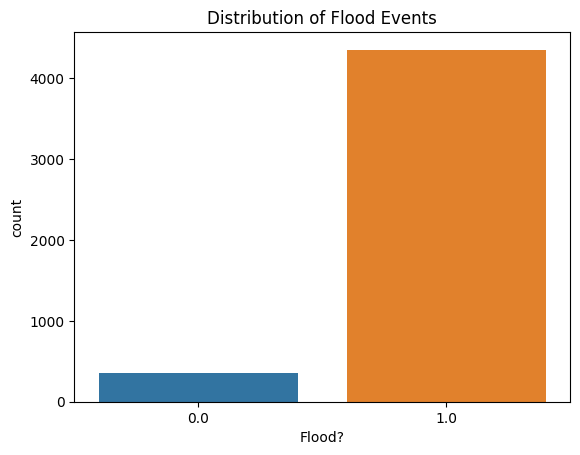

In [ ]:
sns.countplot(x='Flood?', data=df)
plt.title('Distribution of Flood Events')
plt.show()

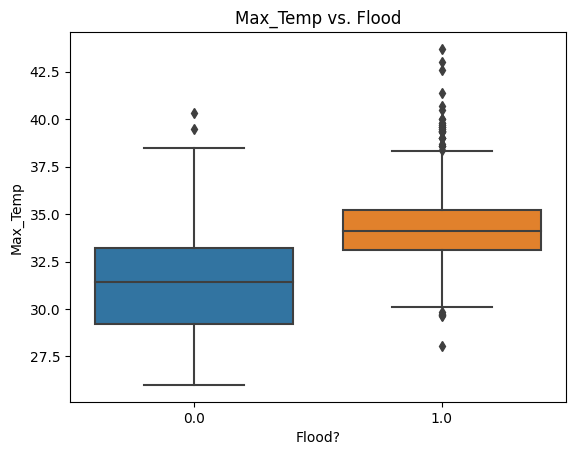

In [ ]:
sns.boxplot(x='Flood?', y='Max_Temp', data=df)
plt.title('Max_Temp vs. Flood')
plt.show()

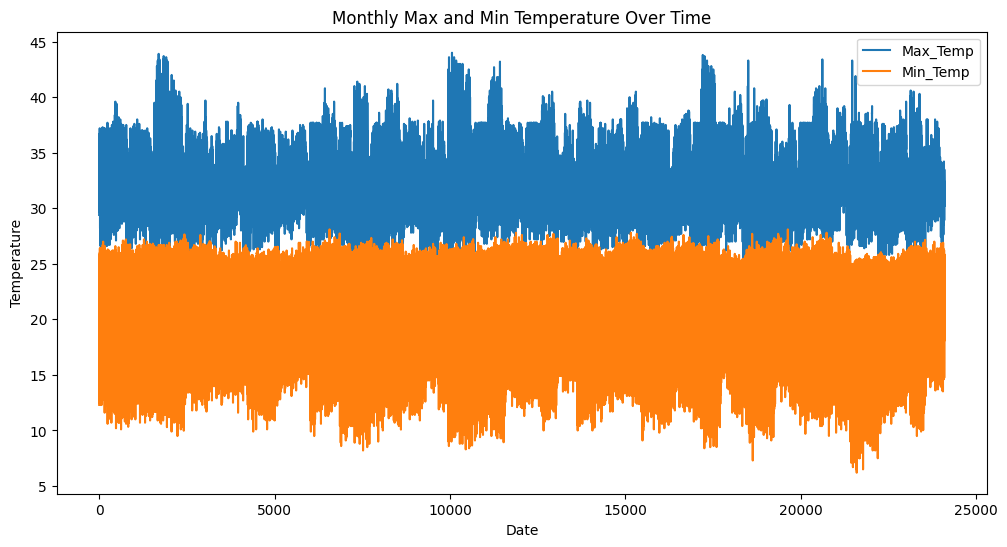

In [ ]:
plt.figure(figsize=(12, 6))
sns.lineplot(x=df.index, y='Max_Temp', label='Max_Temp', data=df)
sns.lineplot(x=df.index, y='Min_Temp', label='Min_Temp', data=df)
plt.title('Monthly Max and Min Temperature Over Time')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.legend()
plt.show()


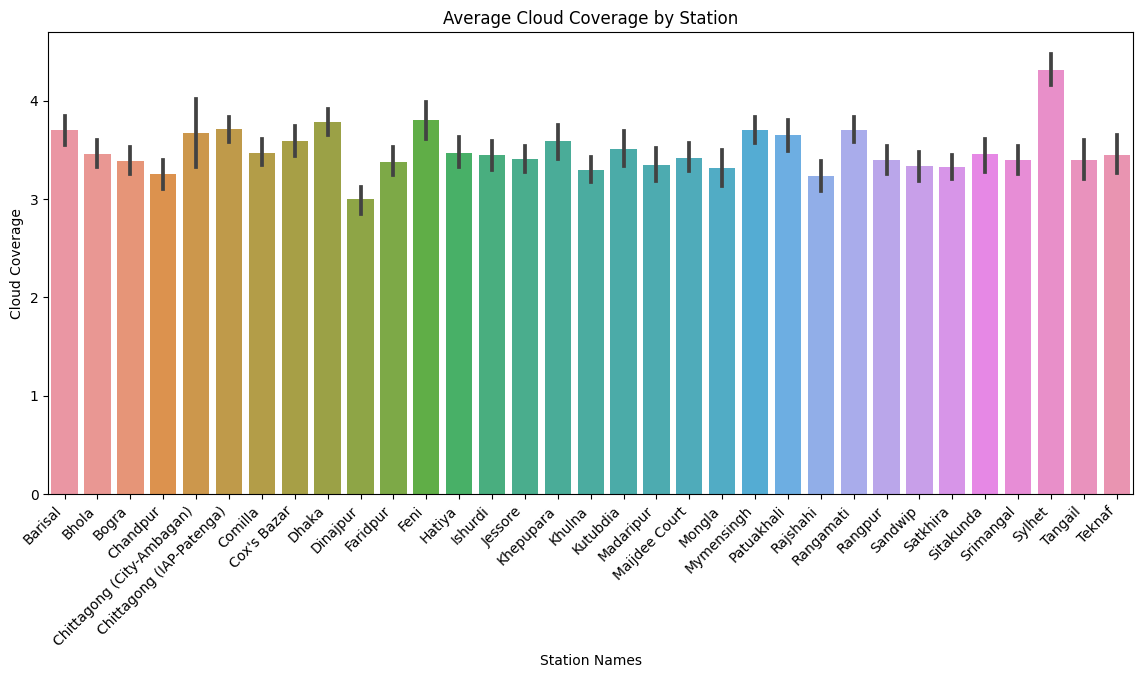

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming 'Cloud_Coverage' and 'Station_Names' are relevant columns
plt.figure(figsize=(14, 6))
sns.barplot(x='Station_Names', y='Cloud_Coverage', data=df)
plt.title('Average Cloud Coverage by Station')
plt.xlabel('Station Names')
plt.ylabel('Cloud Coverage')
plt.xticks(rotation=45, ha='right')
plt.show()

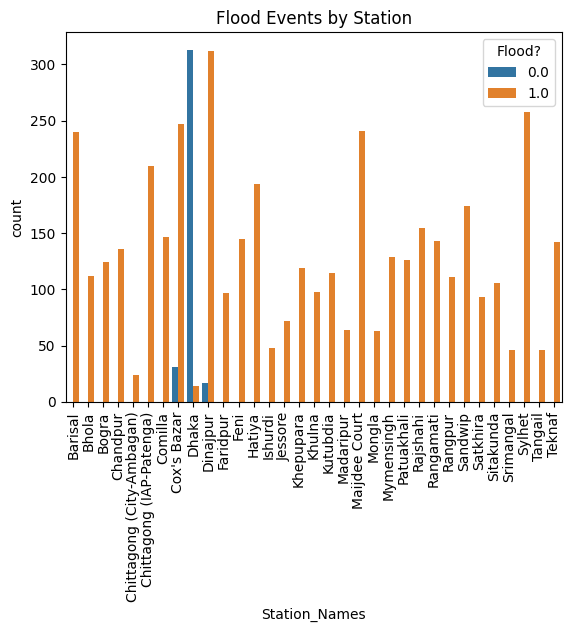

In [ ]:
sns.countplot(x='Station_Names', hue='Flood?', data=df)
plt.title('Flood Events by Station')
plt.xticks(rotation=90)
plt.show()

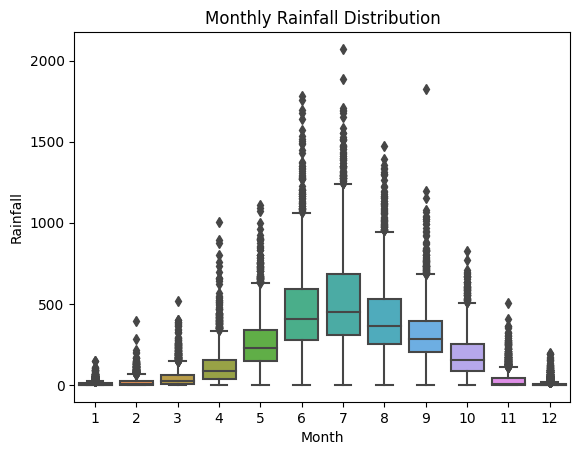

In [ ]:
sns.boxplot(x='Month', y='Rainfall', data=df)
plt.title('Monthly Rainfall Distribution')
plt.show()


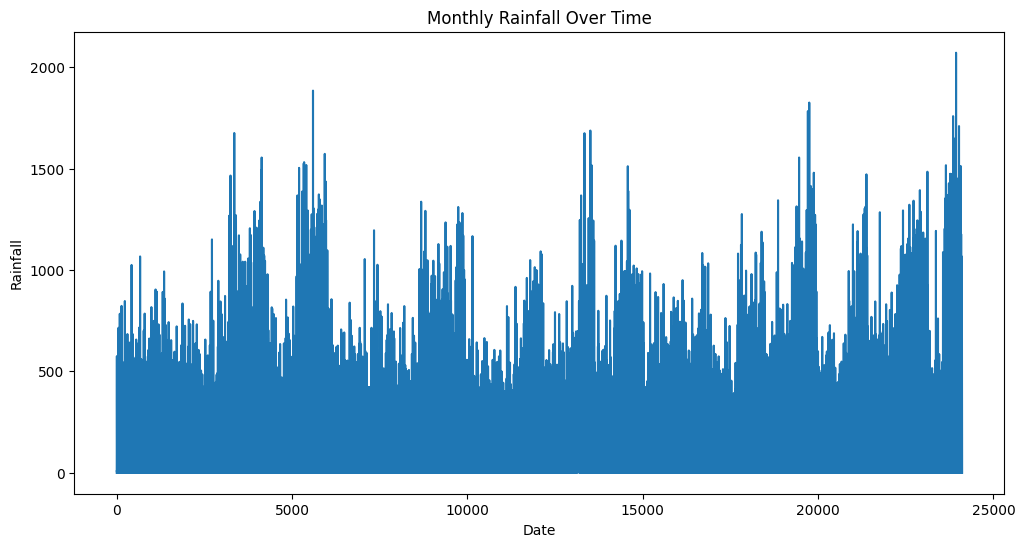

In [ ]:
# Plotting time series for Rainfall
plt.figure(figsize=(12, 6))
sns.lineplot(x=df.index, y='Rainfall', data=df)
plt.title('Monthly Rainfall Over Time')
plt.xlabel('Date')
plt.ylabel('Rainfall')
plt.show()

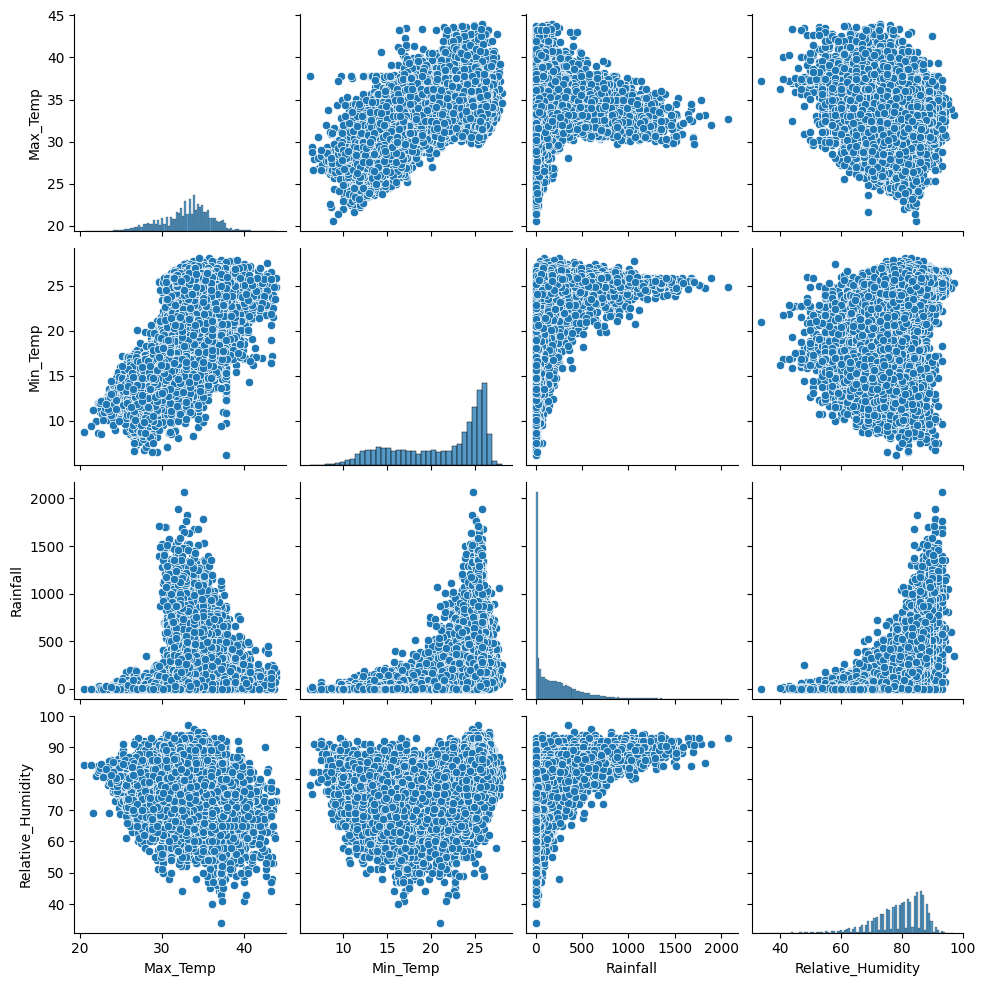

In [ ]:
import seaborn as sns

# Assuming 'Max_Temp', 'Min_Temp', 'Rainfall', 'Relative_Humidity' are relevant columns
sns.pairplot(df[['Max_Temp', 'Min_Temp', 'Rainfall', 'Relative_Humidity']])
plt.show()

<ipython-input-18-64595f2b6ccd>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(df.corr(),annot=True,cmap="YlGnBu",ax=ax)


<Axes: >

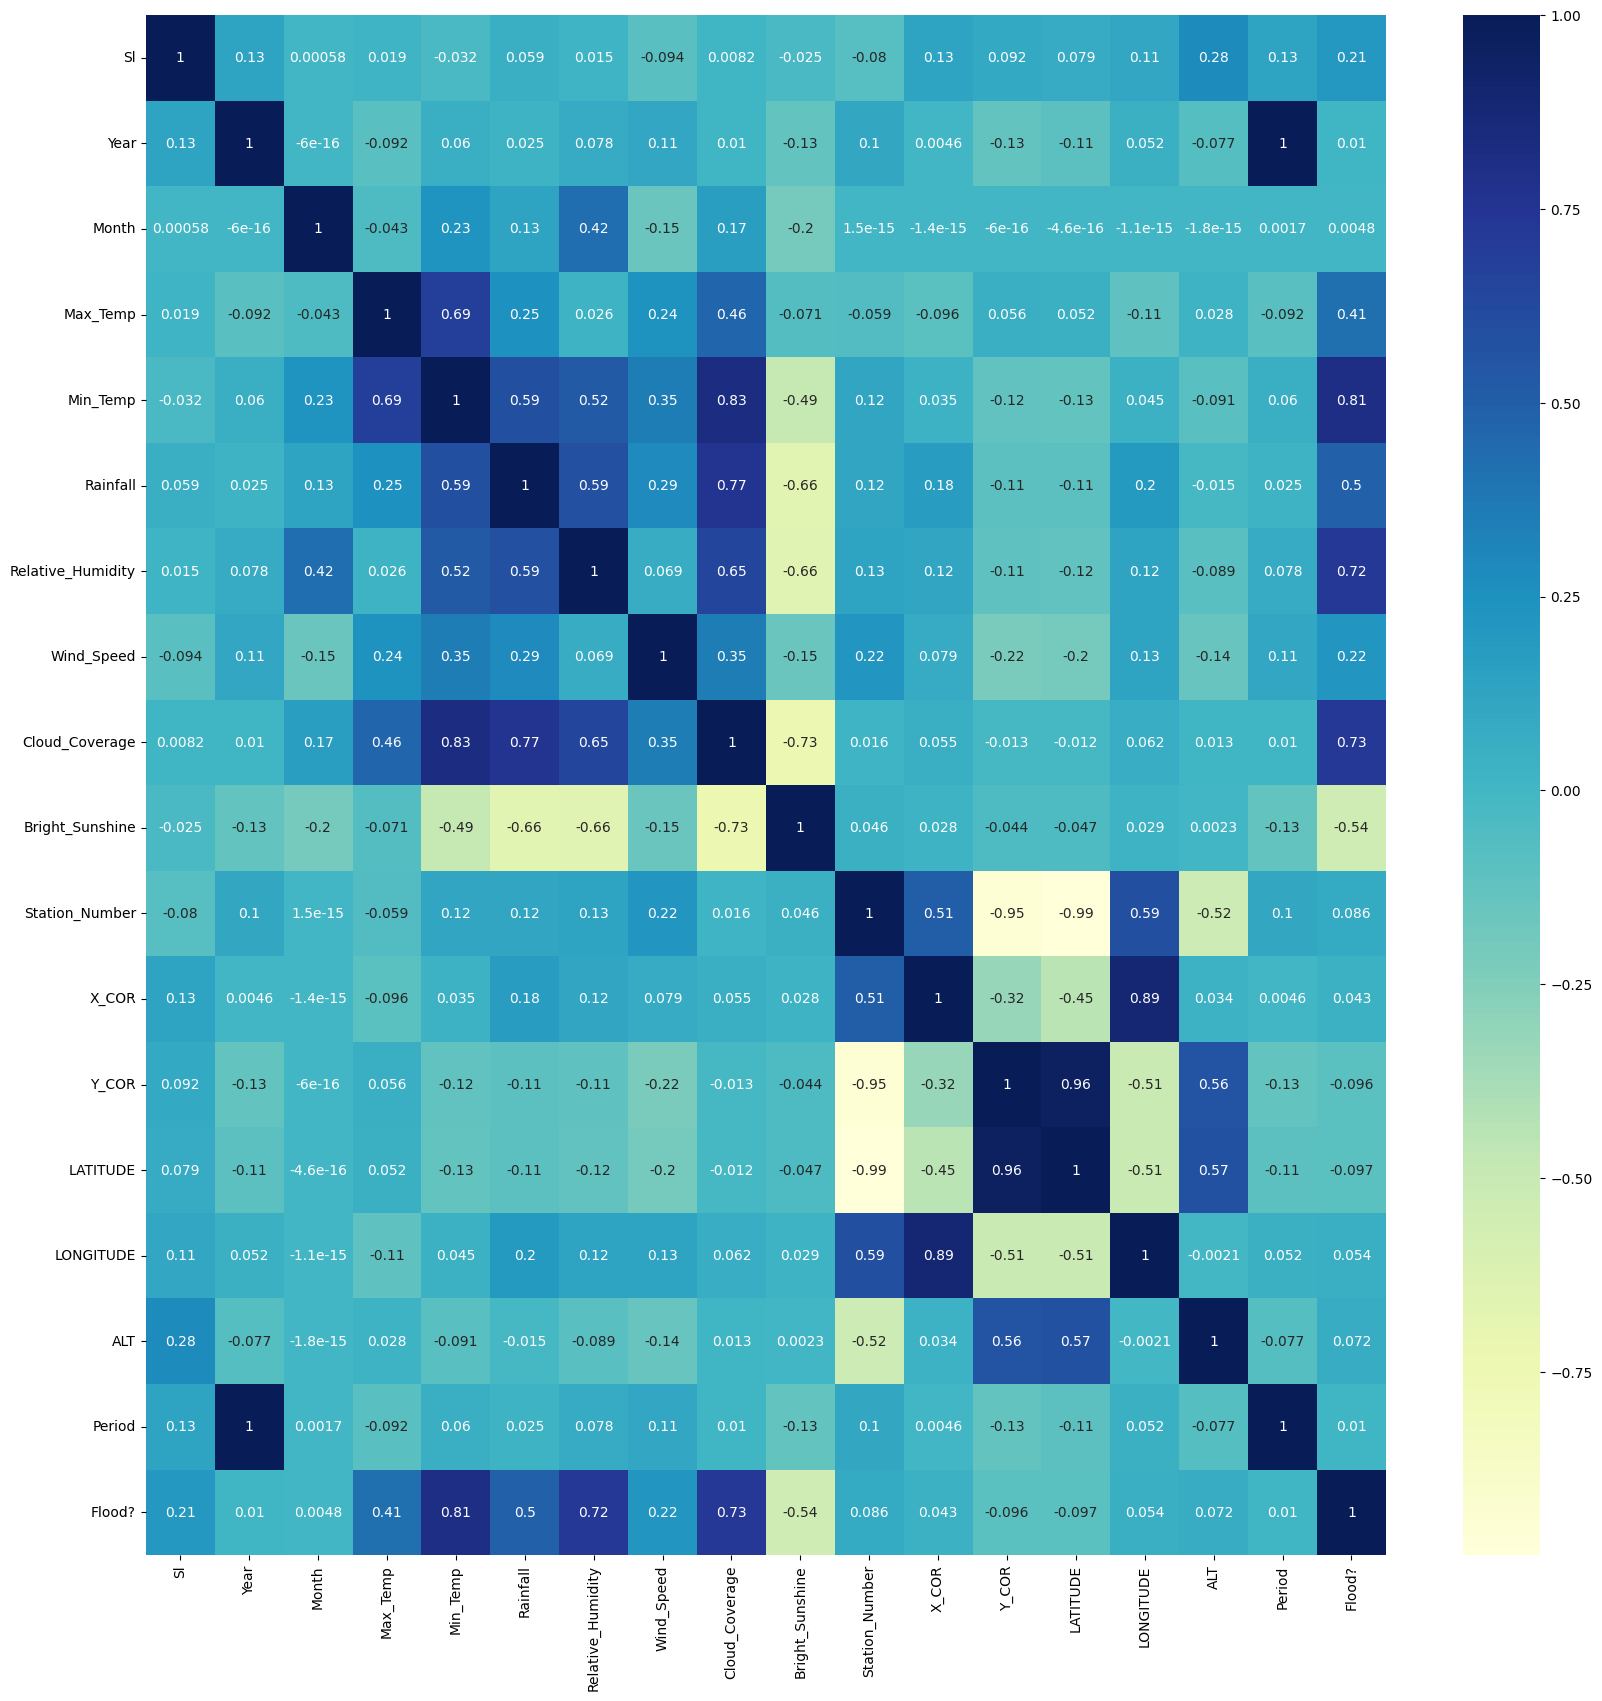

In [ ]:
fig, ax = plt.subplots(figsize=(20,20))
sns.heatmap(df.corr(),annot=True,cmap="YlGnBu",ax=ax)

In [ ]:
df['Flood?'].fillna(0, inplace=True)

In [ ]:
df['Flood?'] = df['Flood?'].astype(int)

In [ ]:
df.isnull().sum()

Sl                   3564
Station_Names           0
Year                    0
Month                   0
Max_Temp                1
Min_Temp                0
Rainfall               12
Relative_Humidity      12
Wind_Speed             12
Cloud_Coverage         16
Bright_Sunshine        26
Station_Number          0
X_COR                   0
Y_COR                   0
LATITUDE                0
LONGITUDE               0
ALT                     0
Period                  0
Flood?                  0
dtype: int64

In [ ]:
columns_to_drop = ['Sl','Station_Names']
flood_data = df.drop(columns=columns_to_drop)


In [ ]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=2)
flood_data_imputed = pd.DataFrame(imputer.fit_transform(flood_data), columns=flood_data.columns)


In [ ]:
X = flood_data_imputed.drop(columns='Flood?')
y = flood_data_imputed['Flood?']

In [ ]:
#train-test-split:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_train_sc = pd.DataFrame(data=X_train_sc,columns=X_train.columns)

X_test_sc = sc.fit_transform(X_test)
X_test_sc = pd.DataFrame(data=X_test_sc,columns=X_test.columns)

In [ ]:
from mlxtend.feature_selection import SequentialFeatureSelector

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
model = DecisionTreeClassifier()
sfs = SequentialFeatureSelector(estimator=model,k_features= 6,forward=True,floating=False,scoring='accuracy',cv=5)
sfs.fit(X_train_sc,y_train)

SequentialFeatureSelector(estimator=DecisionTreeClassifier(), k_features=(6, 6),
                          scoring='accuracy')

In [ ]:
sfs.k_score_

0.9608701064081744

In [ ]:
sel_features_fs = list(sfs.k_feature_names_)
sel_features_fs


['Month', 'Rainfall', 'Station_Number', 'LATITUDE', 'LONGITUDE', 'Period']

In [ ]:
model = DecisionTreeClassifier()
sbe = SequentialFeatureSelector(estimator=model,k_features=6,forward=False,floating=False,scoring='accuracy',cv=5)
sbe.fit(X_train_sc,y_train)

SequentialFeatureSelector(estimator=DecisionTreeClassifier(), forward=False,
                          k_features=(6, 6), scoring='accuracy')

In [ ]:
sbe.k_score_

0.9584274339582162

In [ ]:
sel_features_be = list(sfs.k_feature_names_)
sel_features_be

['Month', 'Rainfall', 'Station_Number', 'LATITUDE', 'LONGITUDE', 'Period']

In [ ]:
# Combine selected features by taking the intersection
combined_features = list(set(sel_features_fs) & set(sel_features_be))
combined_features


['LONGITUDE', 'LATITUDE', 'Period', 'Rainfall', 'Station_Number', 'Month']

In [ ]:
X_train_fe_fsbe = X_train_sc[combined_features]
X_test_fe_fsbe = X_test_sc[combined_features]

In [ ]:
X_train_fe_fsbe

,LONGITUDE,LATITUDE,Period,Rainfall,Station_Number,Month
0,-1.124180,2.089757,-0.511144,-0.812640,-2.101506,-1.595107
1,-1.755803,0.902351,-0.405673,-0.820893,-1.115032,1.591542
2,-0.086514,1.249039,1.593280,-0.825020,-1.361651,1.301847
3,1.582774,-2.113836,1.092917,0.491406,1.707381,1.012151
4,0.518039,-0.415064,0.838486,-0.825020,0.474288,-1.595107
...,...,...,...,...,...,...
21692,1.104546,0.850347,-1.505373,-0.825020,-0.566991,1.591542
21693,1.330125,-1.602471,-1.010008,-0.825020,1.542969,-1.015716
21694,-0.131630,-0.527738,1.492308,0.858684,0.392082,0.722456
21695,-0.086514,1.249039,-0.709590,-0.478375,-1.361651,-0.726021


### BAGGING

## BG1

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, BaggingClassifier, VotingClassifier, AdaBoostClassifier
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Base classifiers
base_classifier3 = XGBClassifier(random_state=42)
base_classifier4 = AdaBoostClassifier(random_state=42)
base_classifier5 = SVC(probability=True)



# Combine base classifiers using VotingClassifier
voting_classifier = VotingClassifier(
    estimators=[
        ('XG_boost', base_classifier3),
        ('AD_boost', base_classifier4),
        ('svm', base_classifier5)
      ],
    voting='hard'  # 'hard' for majority voting, 'soft' for weighted voting
)

# Bagging with the combined base classifiers
bagging_classifier = BaggingClassifier(base_estimator=voting_classifier, n_estimators=50, random_state=42)

# Fit and predict using the final estimator
bagging_classifier.fit(X_train_fe_fsbe, y_train)
y_pred_final1 = bagging_classifier.predict(X_test_fe_fsbe)

# Compare accuracies
accuracy_final_estimator2 = accuracy_score(y_test, y_pred_final1)

print(f'Accuracy of Random Forest (Final Estimator): {accuracy_final_estimator2:.4f}')


/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


Accuracy of Random Forest (Final Estimator): 0.9544


In [ ]:
conf_matrix2 = confusion_matrix(y_test, y_pred_final1)
classification_rep2 = classification_report(y_test, y_pred_final1)

print(f'Accuracy: {accuracy_final_estimator2:.4f}')
print(f'Confusion Matrix:\n{conf_matrix2}')
print(f'Classification Report:\n{classification_rep2}')

# Precision, Recall, F1 Score
precision2 = precision_score(y_test, y_pred_final1)
recall2 = recall_score(y_test, y_pred_final1)
f1_2 = f1_score(y_test,y_pred_final1 )

print("Precision:", precision1)
print("Recall:", recall1)
print("F1 Score:", f1_2)

# ROC-AUC and PR-AUC
roc_auc2 = roc_auc_score(y_test, y_pred_final1)

print("ROC-AUC:", roc_auc2)
# ROC Curve
fpr, tpr, thresholds_roc = roc_curve(y_test, y_pred_final1)

# Matthews Correlation Coefficient
mcc2 = matthews_corrcoef(y_test, y_pred_final1)
print("Matthews Correlation Coefficient:", mcc2)

# Brier Score
brier2 = brier_score_loss(y_test, y_pred_final1)
print("Brier Score:", brier2)

Accuracy: 0.9544
Confusion Matrix:
[[1958   50]
 [  60  343]]
Classification Report:
              precision    recall  f1-score   support

         0.0       0.97      0.98      0.97      2008
         1.0       0.87      0.85      0.86       403

    accuracy                           0.95      2411
   macro avg       0.92      0.91      0.92      2411
weighted avg       0.95      0.95      0.95      2411

Precision: 0.9193954659949622
Recall: 0.9057071960297767
F1 Score: 0.8618090452261307
ROC-AUC: 0.9131081134518996
Matthews Correlation Coefficient: 0.8345862809634016
Brier Score: 0.045624222314392365


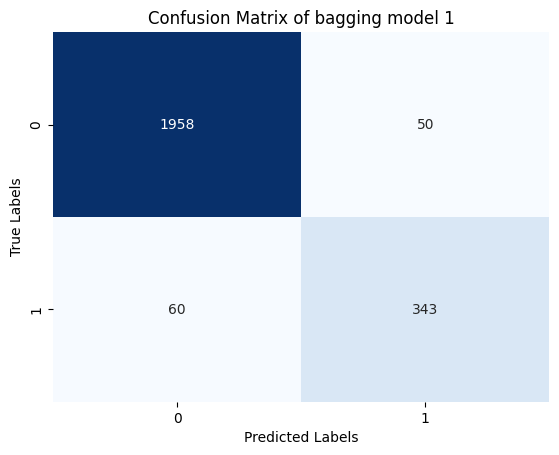

In [ ]:
# Confusion Matrix
sns.heatmap(conf_matrix2, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix of bagging model 1')
plt.show()

## BG2

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, BaggingClassifier, VotingClassifier, AdaBoostClassifier
from sklearn.datasets import make_classification
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Base classifiers
base_classifier1 = DecisionTreeClassifier(random_state=42)
base_classifier2 = RandomForestClassifier(random_state=42)
base_classifier3 = XGBClassifier(random_state=42)


# Combine base classifiers using VotingClassifier
voting_classifier = VotingClassifier(
    estimators=[
        ('decision_tree', base_classifier1),
        ('random_forest', base_classifier2),
        ('XG_boost', base_classifier3)
    ],
    voting='hard'  # 'hard' for majority voting, 'soft' for weighted voting
)

# Bagging with the combined base classifiers
bagging_classifier = BaggingClassifier(base_estimator=voting_classifier, n_estimators=50, random_state=42)

# Fit and predict using the final estimator
bagging_classifier.fit(X_train_fe_fsbe, y_train)
y_pred_final2 = bagging_classifier.predict(X_test_fe_fsbe)

# Compare accuracies
accuracy_final_estimator3 = accuracy_score(y_test, y_pred_final2)

print(f'Accuracy of Random Forest (Final Estimator): {accuracy_final_estimator3:.4f}')


/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


Accuracy of Random Forest (Final Estimator): 0.9722


In [ ]:
conf_matrix3 = confusion_matrix(y_test, y_pred_final2)
classification_rep3 = classification_report(y_test, y_pred_final2)

print(f'Accuracy: {accuracy_final_estimator3:.4f}')
print(f'Confusion Matrix:\n{conf_matrix3}')
print(f'Classification Report:\n{classification_rep3}')

# Precision, Recall, F1 Score
precision3 = precision_score(y_test, y_pred_final2)
recall3 = recall_score(y_test, y_pred_final2)
f1_3 = f1_score(y_test,y_pred_final2)

print("Precision:", precision3)
print("Recall:", recall3)
print("F1 Score:", f1_3)

# ROC-AUC and PR-AUC
roc_auc3 = roc_auc_score(y_test, y_pred_final2)

print("ROC-AUC:", roc_auc3)

# ROC Curve
fpr, tpr, thresholds_roc = roc_curve(y_test, y_pred_final2)

# Matthews Correlation Coefficient
mcc3 = matthews_corrcoef(y_test, y_pred_final2)
print("Matthews Correlation Coefficient:", mcc3)

# Brier Score
brier3 = brier_score_loss(y_test, y_pred_final2)
print("Brier Score:", brier3)

Accuracy: 0.9722
Confusion Matrix:
[[1977   31]
 [  36  367]]
Classification Report:
              precision    recall  f1-score   support

         0.0       0.98      0.98      0.98      2008
         1.0       0.92      0.91      0.92       403

    accuracy                           0.97      2411
   macro avg       0.95      0.95      0.95      2411
weighted avg       0.97      0.97      0.97      2411

Precision: 0.9221105527638191
Recall: 0.9106699751861043
F1 Score: 0.9163545568039951
ROC-AUC: 0.9476158640870761
Matthews Correlation Coefficient: 0.89971802154702
Brier Score: 0.02778929904603899


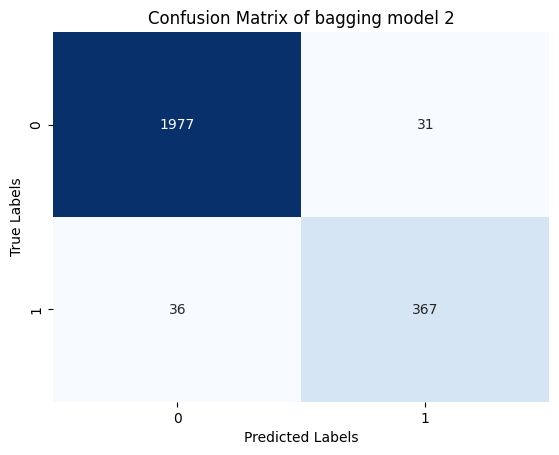

In [ ]:
# Confusion Matrix
sns.heatmap(conf_matrix3, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix of bagging model 2')
plt.show()

## Stacking

In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, BaggingClassifier, VotingClassifier, AdaBoostClassifier
from sklearn.datasets import make_classification
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Base classifiers
base_classifier1 = DecisionTreeClassifier(random_state=42)
base_classifier2 = RandomForestClassifier(random_state=42)
base_classifier3 = XGBClassifier(random_state=42)


# Final estimator (meta-classifier)
final_estimator = LogisticRegression()

# Combine base classifiers using StackingClassifier
stacking_classifier = StackingClassifier(
    estimators=[
        ('decision_tree', base_classifier1),
        ('random_forest', base_classifier2),
        ('XG_boost', base_classifier3)
    ],
    final_estimator=final_estimator,  # meta-classifier
    stack_method='auto',  # method used to train the base classifiers ('auto', 'predict_proba', 'decision_function', or None)
)

# Train the stacking classifier
stacking_classifier.fit(X_train_fe_fsbe, y_train)

# Make predictions on the test set
stacking_predictions1 = stacking_classifier.predict(X_test_fe_fsbe)

# Evaluate the stacking classifier
accuracy5 = accuracy_score(y_test, stacking_predictions1)
print(f"Stacking Classifier Accuracy: {accuracy5:.4f}")

Stacking Classifier Accuracy: 0.9689


In [ ]:
conf_matrix5 = confusion_matrix(y_test, stacking_predictions1)
classification_rep5 = classification_report(y_test, stacking_predictions1)

print(f'Accuracy: {accuracy5:.4f}')
print(f'Confusion Matrix:\n{conf_matrix5}')
print(f'Classification Report:\n{classification_rep5}')

# Precision, Recall, F1 Score
precision5 = precision_score(y_test, stacking_predictions1)
recall5 = recall_score(y_test, stacking_predictions1)
f1_5 = f1_score(y_test,stacking_predictions1)

print("Precision:", precision5)
print("Recall:", recall5)
print("F1 Score:", f1_5)

# ROC-AUC and PR-AUC
roc_auc5 = roc_auc_score(y_test, stacking_predictions1)

print("ROC-AUC:", roc_auc5)

# ROC Curve
fpr, tpr, thresholds_roc = roc_curve(y_test, stacking_predictions1)

# Matthews Correlation Coefficient
mcc5 = matthews_corrcoef(y_test, stacking_predictions1)
print("Matthews Correlation Coefficient:", mcc5)

# Brier Score
brier5 = brier_score_loss(y_test, stacking_predictions1)
print("Brier Score:", brier5)

Accuracy: 0.9689
Confusion Matrix:
[[1978   30]
 [  45  358]]
Classification Report:
              precision    recall  f1-score   support

         0.0       0.98      0.99      0.98      2008
         1.0       0.92      0.89      0.91       403

    accuracy                           0.97      2411
   macro avg       0.95      0.94      0.94      2411
weighted avg       0.97      0.97      0.97      2411

Precision: 0.9226804123711341
Recall: 0.8883374689826302
F1 Score: 0.9051833122629582
ROC-AUC: 0.9366986149694029
Matthews Correlation Coefficient: 0.8868136787332036
Brier Score: 0.031107424305267525


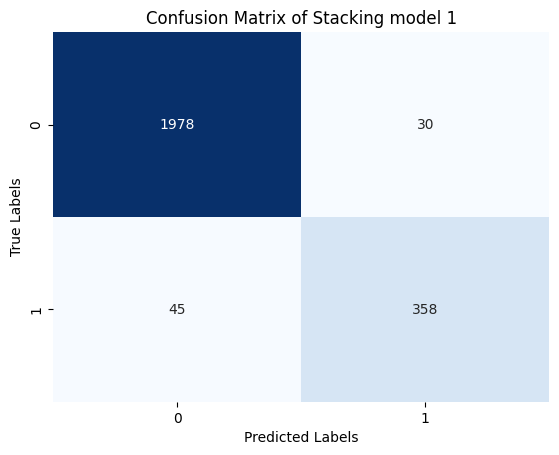

In [ ]:
# Confusion Matrix
sns.heatmap(conf_matrix5, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix of Stacking model 1')
plt.show()

In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, BaggingClassifier, VotingClassifier, AdaBoostClassifier
from sklearn.datasets import make_classification
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Base classifiers
base_classifier3 = XGBClassifier(random_state=42)
base_classifier4 = AdaBoostClassifier(random_state=42)
base_classifier5 = SVC(probability=True)


# Final estimator (meta-classifier)
final_estimator = DecisionTreeClassifier()

# Combine base classifiers using StackingClassifier
stacking_classifier = StackingClassifier(
    estimators=[
        ('XG_boost', base_classifier3),
        ('AD_boost', base_classifier4),
        ('svm', base_classifier5)
    ],
    final_estimator=final_estimator,  # meta-classifier
    stack_method='auto',  # method used to train the base classifiers ('auto', 'predict_proba', 'decision_function', or None)
)

# Train the stacking classifier
stacking_classifier.fit(X_train_fe_fsbe, y_train)

# Make predictions on the test set
stacking_predictions2 = stacking_classifier.predict(X_test_fe_fsbe)

# Evaluate the stacking classifier
accuracy6 = accuracy_score(y_test, stacking_predictions2)
print(f"Stacking Classifier Accuracy: {accuracy6:.4f}")

Stacking Classifier Accuracy: 0.9490


In [ ]:
conf_matrix6 = confusion_matrix(y_test, stacking_predictions2)
classification_rep6 = classification_report(y_test, stacking_predictions2)

print(f'Accuracy: {accuracy6:.4f}')
print(f'Confusion Matrix:\n{conf_matrix6}')
print(f'Classification Report:\n{classification_rep6}')

# Precision, Recall, F1 Score
precision6 = precision_score(y_test, stacking_predictions2)
recall6 = recall_score(y_test, stacking_predictions2)
f1_6 = f1_score(y_test,stacking_predictions2)

print("Precision:", precision6)
print("Recall:", recall6)
print("F1 Score:", f1_6)

# ROC-AUC and PR-AUC
roc_auc6 = roc_auc_score(y_test, stacking_predictions2)

print("ROC-AUC:", roc_auc6)

# ROC Curve
fpr, tpr, thresholds_roc = roc_curve(y_test, stacking_predictions2)

# Matthews Correlation Coefficient
mcc6 = matthews_corrcoef(y_test, stacking_predictions2)
print("Matthews Correlation Coefficient:", mcc6)

# Brier Score
brier6 = brier_score_loss(y_test, stacking_predictions2)
print("Brier Score:", brier6)

Accuracy: 0.9490
Confusion Matrix:
[[1942   66]
 [  57  346]]
Classification Report:
              precision    recall  f1-score   support

         0.0       0.97      0.97      0.97      2008
         1.0       0.84      0.86      0.85       403

    accuracy                           0.95      2411
   macro avg       0.91      0.91      0.91      2411
weighted avg       0.95      0.95      0.95      2411

Precision: 0.8398058252427184
Recall: 0.858560794044665
F1 Score: 0.849079754601227
ROC-AUC: 0.9128461340741253
Matthews Correlation Coefficient: 0.8184602464418946
Brier Score: 0.05101617586063874


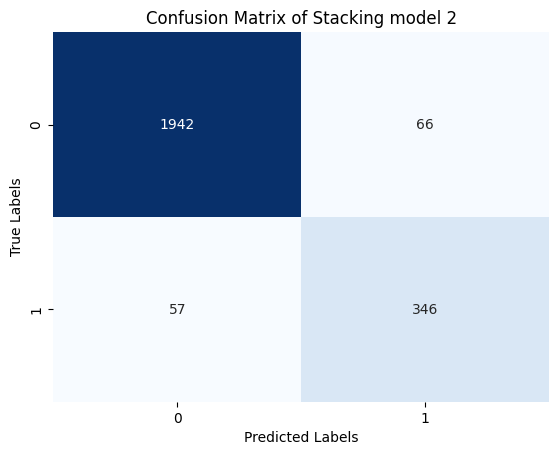

In [ ]:
# Confusion Matrix
sns.heatmap(conf_matrix6, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix of Stacking model 2')
plt.show()